# Assignment 3: Predictive Analytics

In [20]:
# importing data & dependencies
from pathlib import Path
import pandas as pd
import numpy as np
import sklearn as sk



# Define the paths relative to your notebook's directory
clinic_path = Path("data") / "clinic_appointments_O712.xlsx"
newapp_path = Path("data") / "new_appointments_O712.xlsx"

# Load both into separate DataFrames
df_clinic = pd.read_excel(clinic_path)
df_newapp = pd.read_excel(newapp_path)

In [ ]:
#Highlevel scan of the data

# df_clinic.head(5)
# df_clinic.info()
# print(df_clinic.duplicated().sum())
# print(df_clinic.isna().sum()) #wait_time_min 1021
# df_clinic.describe()
df_clinic.sample(5)

,appointment_id,booking_date,appointment_date,appointment_hour,service,age,sex,distance_km,new_patient,prior_appointments,prior_no_shows,booking_channel,coverage,patient_fee_cad,sms_reminder,wait_time_min,status
2529,A100596,2025-06-08,2025-06-09,9,Family medicine,52,F,4.1,0,4,0,Phone,Provincial plan,0,1,24.0,Attended
5496,A102005,2025-12-02,2025-12-03,13,Family medicine,40,F,1.9,0,10,2,Phone,Provincial plan,0,1,4.0,Attended
2756,A102453,2025-04-01,2025-06-20,17,Dermatology,65,M,15.4,0,5,0,Physician referral,Provincial plan,0,0,24.0,Attended
1028,A103743,2025-03-03,2025-03-07,10,Physiotherapy,52,F,7.4,1,0,0,Online portal,Private insurance,20,1,0.0,No-show
5406,A104345,2025-10-15,2025-11-28,10,Dermatology,24,M,2.4,1,0,0,Online portal,Provincial plan,0,1,0.0,No-show


## Part 1: Framing and fitting a classifier

#### A) *Based on the note, what exactly should your model predict?*
- The note is centred around predicting "No-shows", as the support staff are unable to fill the appointment slot given that there is no prior warning until the moment a no-show is realized.
- The target variable is transformed into a binary, with the other variables treated as the non-relevant values (O).
- Based on the data, we are trying to predict around 13.5% of the cases, which is about 1/7.5 cases.

#### B) *Which columns to exclude from the features*
- First, we must exclude the target column (no_show), along with anything that may lead to leakage: status and wait_time.
- We can also exclude appointment_id and the booking/appointment date, as the former is an arbitrary unique ID and the latter are raw dates with no predictive power unless transformed into a feature.

#### C) *Split the data into 70% training and 30% test -  Fit the workflow on the training set and show the confusion matrix on the test set using the default threshold*
- See cell 7
- We can see that the confusion matrix only raised the flag 34 times, of which only half were valid; as such, this model is not very precise.

#### D) *Compare the analysts accuracy with your model’s*
- The analyst’s model predicts that no appointment in the test set will be a no-show. It gets all 1,557 attended or cancelled appointments right and all 243 no-shows wrong, for an accuracy of 1,557 / 1,800 = 0.865.
- Whereas the logisitic model also scores  0.865. It correctly flags 17 no-shows, but it also wrongly flags 17 appointments that turned out fine. 
- With respect to accuracy, the models are on par; however, from the business's perspective, accuracy isn't useful, whereas as our model was able to flag 17/243 no-shows. 


In [ ]:
# Code for A

# creating our target variable
df_clinic['no_show'] = (df_clinic['status'] == 'No-show').astype(int)

# Measuring repsective counts and average
print(df_clinic['no_show'].value_counts())
print(f"No-show share: {df_clinic['no_show'].mean():.2%}")

no_show
0    5191
1     809
Name: count, dtype: int64
No-show share: 13.48%


[[1540   17]
 [ 226   17]]


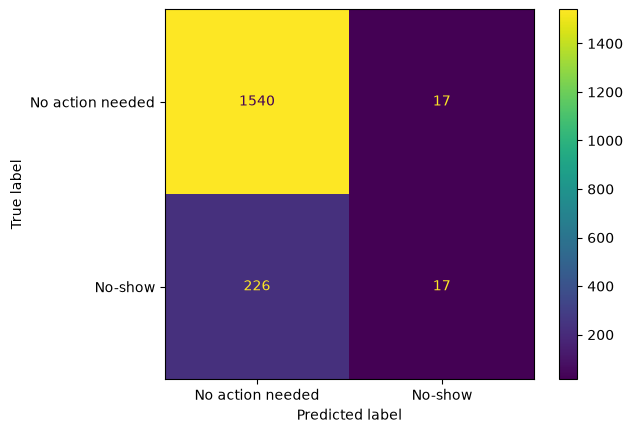

In [ ]:
#Code for part C

# Importing dependencies

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


# Define features (X) and target (y) from df_clinic
cols_to_drop = [
    'appointment_id',
    'booking_date',
    'appointment_date',
    'wait_time_min',
    'status',
    'no_show'
]

# Features and target
X = df_clinic.drop(columns=cols_to_drop)
y = df_clinic['no_show']

# 70/30 split, stratified so both sets keep the same no-show share
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)

# Split columns by type
cat_cols = X.select_dtypes(include=['object', 'string']).columns.tolist()
num_cols = X.select_dtypes(include='number').columns.tolist()

# Preprocessing: scale numeric, one-hot encode categorical
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

# Workflow = preprocessing + classifier
logit_pipe = Pipeline([
    ('preprocess', preprocessor),
    ('model', LogisticRegression(max_iter=1000, random_state=42))
])

logit_pipe.fit(X_train, y_train)

# Confusion matrix on the test set at the default 0.5 threshold
y_pred = logit_pipe.predict(X_test)

print(confusion_matrix(y_test, y_pred))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=['No action needed', 'No-show']
)